In [ ]:
# # Mount Drive
# from google.colab import drive
# drive.mount('/content/drive')

# Imports
import os, random, math
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from PIL import Image, ImageOps

# Constants
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32            # reduce to 16 if you hit OOM
NUM_CLASSES = 5            # adjust if necessary
TARGET_PER_CLASS = 500     # per your request
AUTOTUNE = tf.data.AUTOTUNE

# Paths (adjust to your Drive layout)
BASE_PATH = '/content/drive/MyDrive/Wheat_Images'               # original dataset arranged per-class
OUTPUT_BASE = '/content/drive/MyDrive'       # where train/val/test/balanced will be referenced
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_BASE, 'Wheat_Output')
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# class names - MUST match your folder names under BASE_PATH
CLASS_NAMES = ['Crown and Root Rot', 'Healthy Wheat', 'Leaf Rust', 'Septoria', 'Stripe Rust']
CLASS_TO_INDEX = {c:i for i,c in enumerate(CLASS_NAMES)}

In [ ]:
# collect file lists per class
per_class_files = {}
for cls in CLASS_NAMES:
    cls_dir = os.path.join(BASE_PATH, cls)
    files = [os.path.join(cls_dir, f) for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    random.shuffle(files)
    per_class_files[cls] = files

# create balanced lists (oversample with replacement when needed)
balanced_paths = []
balanced_labels = []
for cls in CLASS_NAMES:
    files = per_class_files[cls]
    n = len(files)
    if n == 0:
        raise ValueError(f"No files found for class {cls} in {os.path.join(BASE_PATH, cls)}")
    # if enough files, sample without replacement; otherwise sample with replacement
    if n >= TARGET_PER_CLASS:
        chosen = random.sample(files, TARGET_PER_CLASS)
    else:
        chosen = list(files) + [random.choice(files) for _ in range(TARGET_PER_CLASS - n)]
        random.shuffle(chosen)
    balanced_paths += chosen
    balanced_labels += [CLASS_TO_INDEX[cls]] * TARGET_PER_CLASS

# Shuffle balanced set (global)
combined = list(zip(balanced_paths, balanced_labels))
random.shuffle(combined)
balanced_paths, balanced_labels = zip(*combined)
balanced_paths = list(balanced_paths)
balanced_labels = list(balanced_labels)

print("Balanced dataset created:", len(balanced_paths), "images (should be", TARGET_PER_CLASS * len(CLASS_NAMES), ")")


Balanced dataset created: 2500 images (should be 2500 )


In [ ]:
from sklearn.model_selection import train_test_split

# Stratified split: train 80% / val 10% / test 10%
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    balanced_paths, balanced_labels, test_size=0.20, stratify=balanced_labels, random_state=42)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42)

print("Train:", len(train_paths), "Val:", len(val_paths), "Test:", len(test_paths))


Train: 2000 Val: 250 Test: 250


In [ ]:
def _read_and_decode(path, label):
    # path: scalar string tensor, label: scalar int
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)   # returns uint8
    image.set_shape([None, None, 3])   # gives TF a shape hint -> avoids weird rank issues
    image = tf.cast(image, tf.float32)
    return image, label


In [ ]:
def augment(image, label):
    # image: float32 uint-like [0..255]
    # 1) Resize short side to 244 -> ensure crop works
    # keep aspect by resizing smaller dimension then central/random crop
    # we'll resize so the smallest side >= 244 then random crop 224x224
    # For simplicity use tf.image.resize to (244,244) first (safe and deterministic)
    image = tf.image.resize(image, [244, 244])  # float32
    image = tf.image.random_crop(image, size=[IMAGE_SIZE[0], IMAGE_SIZE[1], 3])

    # color augmentations
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.08)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.image.random_saturation(image, lower=0.9, upper=1.1)
    image = tf.image.random_hue(image, max_delta=0.02)

    # clip and return
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

def preprocess_only(image, label):
    # Resize to 224 center crop (for val/test)
    image = tf.image.resize_with_pad(image, IMAGE_SIZE[0], IMAGE_SIZE[1])  # preserves aspect
    return image, label


In [ ]:
# utility to create dataset from paths/labels
def make_dataset(paths, labels, training=True):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
    ds = ds.shuffle(buffer_size=len(paths), seed=42) if training else ds
    ds = ds.map(_read_and_decode, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(preprocess_only, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels, training=False)
test_ds = make_dataset(test_paths, test_labels, training=False)

# Quick sanity check shapes
for images, labels in train_ds.take(1):
    print("Train batch shape:", images.shape, labels.shape)  # expect (B,224,224,3) and (B,)
for images, labels in val_ds.take(1):
    print("Val batch shape:", images.shape, labels.shape)


Train batch shape: (32, 224, 224, 3) (32,)
Val batch shape: (32, 224, 224, 3) (32,)


In [ ]:
def build_base(model_name):
    if model_name == "EfficientNetB0":
        base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224,224,3))
        preprocess_fn = tf.keras.applications.efficientnet.preprocess_input
    elif model_name == "MobileNetV2":
        base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(224,224,3))
        preprocess_fn = tf.keras.applications.mobilenet_v2.preprocess_input
    elif model_name == "ResNet50":
        base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(224,224,3))
        preprocess_fn = tf.keras.applications.resnet.preprocess_input
    elif model_name == "EfficientNetV2B0":
        base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet", input_shape=(224,224,3))
        preprocess_fn = tf.keras.applications.efficientnet_v2.preprocess_input
    else:
        raise ValueError("Unknown model")
    return base, preprocess_fn

def train_model(model_name, head_epochs=10, fine_tune_epochs=20, unfreeze_percent=0.2):
    print("="*20, "Training", model_name, "="*20)
    base, preprocess_fn = build_base(model_name)
    base.trainable = False

    inputs = tf.keras.Input(shape=(224,224,3))
    x = layers.Lambda(preprocess_fn)(inputs)          # model-specific preprocessing
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    # callbacks
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.3, verbose=1)

    # Phase 1: train head
    print("Phase 1 — training head (base frozen) for", head_epochs, "epochs")
    history_head = model.fit(train_ds, validation_data=val_ds, epochs=head_epochs, callbacks=[early_stop, reduce_lr])

    # Phase 2: unfreeze top layers of base
    # unfreeze last X% layers
    total_layers = len(base.layers)
    n_unfreeze = max(1, int(total_layers * unfreeze_percent))
    print("Unfreezing last", n_unfreeze, "layers of base model (out of", total_layers, ")")
    for layer in base.layers[-n_unfreeze:]:
        layer.trainable = True

    # recompile with lower LR for fine-tuning
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    print("Phase 2 — fine-tuning for", fine_tune_epochs, "epochs")
    history_ft = model.fit(train_ds, validation_data=val_ds, epochs=fine_tune_epochs, callbacks=[early_stop, reduce_lr])

    # Save model (h5)
    filename = {
        "EfficientNetB0": "efficientnetb0_balanced_500.h5",
        "MobileNetV2": "mobilenetv2_balanced_500.h5",
        "ResNet50": "resnet50_balanced_500.h5",
        "EfficientNetV2B0": "efficientnetv2b0_balanced_500.h5"
    }[model_name]
    model_path = os.path.join(MODEL_OUTPUT_DIR, filename)
    model.save(model_path)
    print("Saved model to:", model_path)
    return model, history_head, history_ft


In [ ]:
# Choose ONE model to train
model_name = "EfficientNetB0"      # <-- change this to MobileNetV2 / ResNet50 / EfficientNetV2B0

model, h1, h2 = train_model(
    model_name,
    head_epochs=10,
    fine_tune_epochs=20,
    unfreeze_percent=0.2
)

# optional: free GPU memory after training
tf.keras.backend.clear_session()

print("\nTraining completed for:", model_name)


==================== Training EfficientNetB0 ====================
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Phase 1 — training head (base frozen) for 10 epochs
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 429s 6s/step - accuracy: 0.4355 - loss: 1.3817 - val_accuracy: 0.7320 - val_loss: 0.8420 - learning_rate: 1.0000e-04
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.7441 - loss: 0.8021 - val_accuracy: 0.8200 - val_loss: 0.6245 - learning_rate: 1.0000e-04
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.8175 - loss: 0.5701 - val_accuracy: 0.8160 - val_loss: 0.5262 - learning_rate: 1.0000e-04
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.8329 - loss: 0.5104 - val_accuracy: 0.8320 - val_loss: 0.4666 - learning_rate: 1.0000e-04
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.8797 - loss: 0.3978 - val_accuracy: 0.8520 - val_loss: 0.4247 - learning_rate: 1.0000e-04
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - acc

Saved model to: /content/drive/MyDrive/Wheat_Output/efficientnetb0_balanced_500.h5

Training completed for: EfficientNetB0


In [ ]:
model.save('eb0.keras')

In [ ]:
def preprocess_input_image(image_path):
    # Loads with PIL, center-crops to square, resizes to 224x224, returns float32 array
    img = Image.open(image_path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")
    w,h = img.size
    min_dim = min(w,h)
    left = (w - min_dim)//2
    top = (h - min_dim)//2
    img = img.crop((left, top, left+min_dim, top+min_dim))
    img = img.resize((224,224), Image.Resampling.LANCZOS)
    arr = np.array(img).astype(np.float32)
    return arr  # remember: model expects preprocess_input applied inside model (we applied it there)


In [ ]:
# # Mount Drive
# from google.colab import drive
# drive.mount('/content/drive')

# Imports
import os, random, math
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from PIL import Image, ImageOps

# Constants
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32            # reduce to 16 if you hit OOM
NUM_CLASSES = 5            # adjust if necessary
TARGET_PER_CLASS = 500     # per your request
AUTOTUNE = tf.data.AUTOTUNE

# Paths (adjust to your Drive layout)
BASE_PATH = '/content/drive/MyDrive/Wheat_Images'               # original dataset arranged per-class
OUTPUT_BASE = '/content/drive/MyDrive'       # where train/val/test/balanced will be referenced
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_BASE, 'Wheat_Output')
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# class names - MUST match your folder names under BASE_PATH
CLASS_NAMES = ['Crown and Root Rot', 'Healthy Wheat', 'Leaf Rust', 'Septoria', 'Stripe Rust']
CLASS_TO_INDEX = {c:i for i,c in enumerate(CLASS_NAMES)}


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.models import load_model

mp = os.path.join(MODEL_OUTPUT_DIR, "efficientnetb0_balanced_500.h5")

m = load_model(
    mp,
    compile=False,
    custom_objects={"preprocess_input": preprocess_input}
)

img_arr = preprocess_input_image('/content/drive/MyDrive/Wheat_Images/Septoria/Septoria1886.png')
img_batch = np.expand_dims(img_arr, 0)  # (1,224,224,3)
pred = m.predict(img_batch)
pred_class = np.argmax(pred, axis=1)[0]
print("Predicted class index:", pred_class, "->", CLASS_NAMES[pred_class])


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted class index: 3 -> Septoria


In [ ]:
def evaluate_model(model, test_dataset, class_names):
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
    import seaborn as sns

    y_true = []
    y_pred = []

    # 🔹 Predict on full test dataset
    for images, labels in test_dataset:
        preds = model.predict(images, verbose=0)
        preds_class = np.argmax(preds, axis=1)

        y_true.extend(labels.numpy())
        y_pred.extend(preds_class)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # ------------------------------
    # 1️⃣ ACCURACY
    # ------------------------------
    acc = accuracy_score(y_true, y_pred)
    print("\n========================")
    print(" Test Accuracy:", round(acc * 100, 2), "%")
    print("========================\n")

    # ------------------------------
    # 2️⃣ CLASSIFICATION REPORT
    # ------------------------------
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # ------------------------------
    # 3️⃣ CONFUSION MATRIX
    # ------------------------------
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()


In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.efficientnet import preprocess_input

model_path = os.path.join(MODEL_OUTPUT_DIR, "efficientnetb0_balanced_500.h5")

model_e0 = load_model(
    model_path,
    compile=False,
    custom_objects={"preprocess_input": preprocess_input}
)


In [ ]:
class_names = ["Crown and Root Rot", "Healthy Wheat", "Leaf Rust", "Septoria", "Stripe Rust"]



 Test Accuracy: 80.8 %

Classification Report:
                    precision    recall  f1-score   support

Crown and Root Rot       0.80      0.82      0.81        50
     Healthy Wheat       0.65      0.92      0.76        50
         Leaf Rust       0.92      0.70      0.80        50
          Septoria       0.95      0.72      0.82        50
       Stripe Rust       0.85      0.88      0.86        50

          accuracy                           0.81       250
         macro avg       0.83      0.81      0.81       250
      weighted avg       0.83      0.81      0.81       250



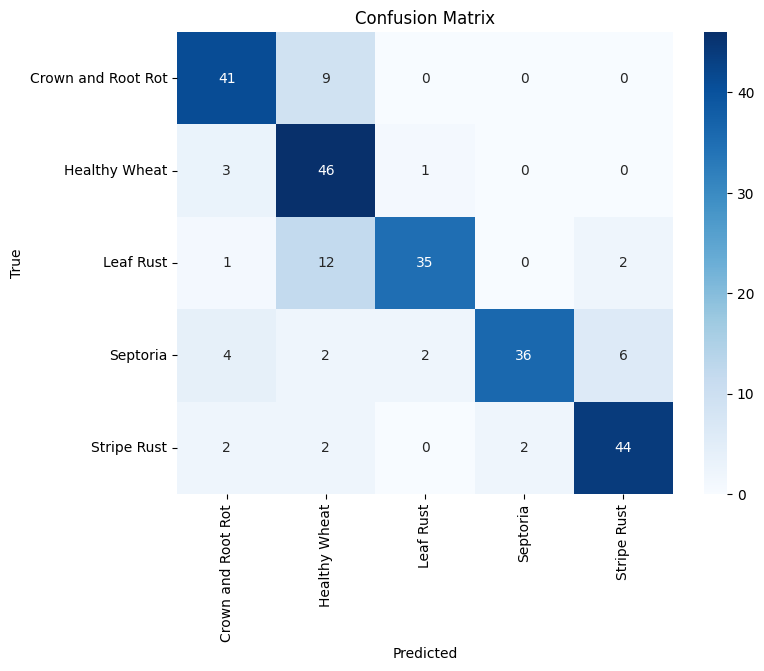

In [ ]:
evaluate_model(model_e0, test_ds, class_names)
